In [3]:
import os                                   # environment variables and folder creation
import os.path as op                        # op.join() builds file paths
import shutil                               # shutil.which() checks that an FSL program is found
import subprocess                           # runs FSL command-line tools from Python
import matplotlib.pyplot as plt             # figures
from matplotlib.colors import ListedColormap  # custom colours for the tissue segmentation
from matplotlib.patches import Patch        # coloured boxes for the segmentation legend
from nilearn import plotting                # brain image plotting


data_dir = op.expanduser("~/Desktop/NSSP-Mini-project-1/data")   # <- change to where your data really is
out_dir = op.expanduser("~/Desktop/NSSP-Mini-project-1/results/part1")  # all outputs of Part 1 go here

# ---- input / output paths, built with op.join ----
t1_path = op.join(data_dir, "T1", "T1w.nii.gz")   # original structural image
fig_dir = op.join(out_dir, "figures")               # folder for the saved figures
os.makedirs(fig_dir, exist_ok=True)                 # create output folders (no error if they exist)

# ---- FSL environment (needed when running inside Jupyter) ----
fsldir = os.environ.get("FSLDIR", op.expanduser("~/fsl"))  # FSL install folder (default of the Mac installer)
os.environ["FSLDIR"] = fsldir                       # make sure FSL tools can find their files
os.environ["FSLOUTPUTTYPE"] = "NIFTI_GZ"            # FSL writes .nii.gz files
os.environ["PATH"] = os.pathsep.join([op.join(fsldir, "bin"),                 # add FSL programs to the PATH
                                      op.join(fsldir, "share", "fsl", "bin"),
                                      os.environ["PATH"]])

# ---- MNI152 templates shipped with FSL ----
mni_head = op.join(fsldir, "data", "standard", "MNI152_T1_2mm.nii.gz")        # whole-head template
mni_brain = op.join(fsldir, "data", "standard", "MNI152_T1_2mm_brain.nii.gz")  # skull-stripped template

# ---- stop early with a clear message if something is missing ----
assert op.exists(t1_path), f"T1w image not found: {t1_path}"      # wrong data_dir?
assert shutil.which("bet"), f"FSL programs not found (FSLDIR={fsldir})"  # FSL not installed/loaded?
assert op.exists(mni_brain), f"MNI template not found: {mni_brain}"      # wrong FSLDIR?
print("All good. T1w:", t1_path)


All good. T1w: /Users/matt/Desktop/NSSP-Mini-project-1/data/T1/T1w.nii.gz


## 1. skull-stripping with FSL BET

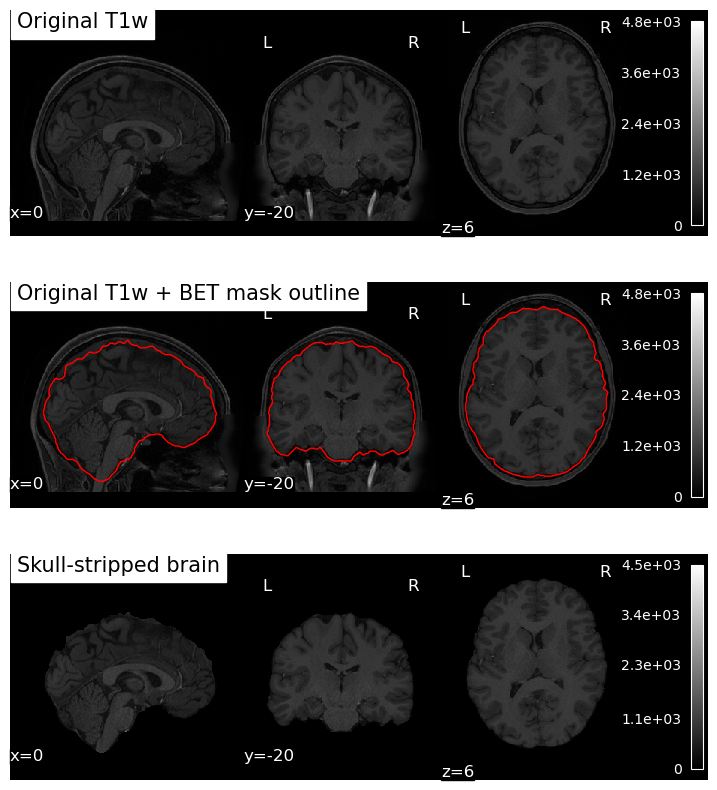

In [ ]:
t1_reori = op.join(out_dir, "T1w_reori.nii.gz")      # T1w with standard orientation
brain_prefix = op.join(out_dir, "T1w_brain")         # BET output name (without extension)
brain = brain_prefix + ".nii.gz"                     # skull-stripped brain image
mask = brain_prefix + "_mask.nii.gz"                 # binary brain mask (created by bet -m)

# put the image in standard (MNI-like) orientation
subprocess.run(["fslreorient2std", t1_path, t1_reori], check=True)

# skull-strip: -R robust centre estimation, -f 0.3 threshold (lower = bigger brain), -m save mask
subprocess.run(["bet", t1_reori, brain_prefix, "-R", "-f", "0.3", "-m"], check=True)

# ---- plot: original / original + mask outline / skull-stripped ----
coords = plotting.find_xyz_cut_coords(mask)          # centre of the brain, used to pick the slices
fig, axs = plt.subplots(3, 1, figsize=(9, 10))       # 3 stacked panels

# panel 1: original T1w
plotting.plot_anat(t1_reori, cut_coords=coords, axes=axs[0], draw_cross=False, title="Original T1w")

# panel 2: original T1w with the brain-mask outline in red (to check the extraction quality)
disp = plotting.plot_anat(t1_reori, cut_coords=coords, axes=axs[1], draw_cross=False,
                          title="Original T1w + BET mask outline")
disp.add_contours(mask, levels=[0.5], colors="r", linewidths=1)  # draw the mask boundary

# panel 3: skull-stripped brain
plotting.plot_anat(brain, cut_coords=coords, axes=axs[2], draw_cross=False, title="Skull-stripped brain")

fig.savefig(op.join(fig_dir, "1_skull_stripping.png"), dpi=200, bbox_inches="tight")  # save figure
plt.show()                                           # show it in the notebook

## 2. tissue segmentation with FSL FAST

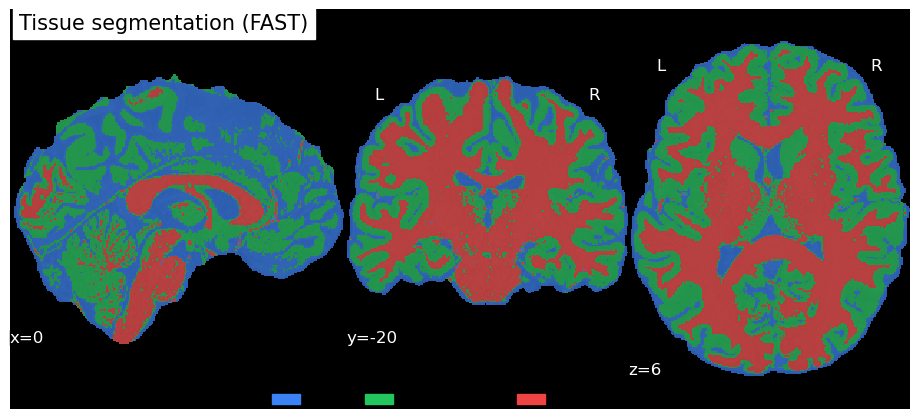

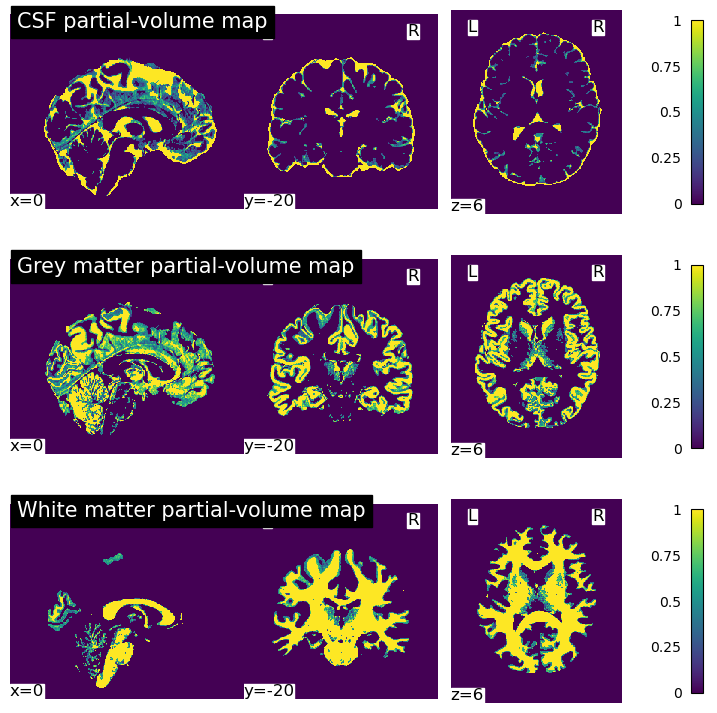

In [5]:

fast_prefix = op.join(out_dir, "T1w_brain_fast")     # FAST output name (without extension)
seg = fast_prefix + "_seg.nii.gz"                    # labelled image: 1 = CSF, 2 = GM, 3 = WM

# FAST: -t 1 = T1 image, -n 3 = three tissue classes, -B/-b = bias-field correction
subprocess.run(["fast", "-t", "1", "-n", "3", "-B", "-b", "-o", fast_prefix, brain], check=True)

# ---- plot 1: segmentation overlaid on the brain ----
cmap = ListedColormap(["#3b82f6", "#22c55e", "#ef4444"])   # colours: CSF blue, GM green, WM red
fig = plt.figure(figsize=(9, 4))
plotting.plot_roi(seg, bg_img=brain, cut_coords=coords, cmap=cmap, vmin=1, vmax=3,
                  alpha=0.7, colorbar=False, draw_cross=False, figure=fig,
                  title="Tissue segmentation (FAST)")
fig.legend(handles=[Patch(color="#3b82f6", label="CSF"),            # legend explaining the colours
                    Patch(color="#22c55e", label="Grey matter"),
                    Patch(color="#ef4444", label="White matter")],
           loc="lower center", ncol=3, frameon=False)
fig.savefig(op.join(fig_dir, "2_segmentation.png"), dpi=200, bbox_inches="tight")
plt.show()

# ---- plot 2: partial-volume maps (probability of each tissue in every voxel) ----
fig, axs = plt.subplots(3, 1, figsize=(9, 9))              # one panel per tissue
for i, name in enumerate(["CSF", "Grey matter", "White matter"]):
    plotting.plot_img(f"{fast_prefix}_pve_{i}.nii.gz", cut_coords=coords, axes=axs[i],
                      cmap="viridis", vmin=0, vmax=1, colorbar=True, draw_cross=False,
                      title=f"{name} partial-volume map")
fig.savefig(op.join(fig_dir, "2b_pve_maps.png"), dpi=200, bbox_inches="tight")
plt.show()

## 3. registration to MNI space

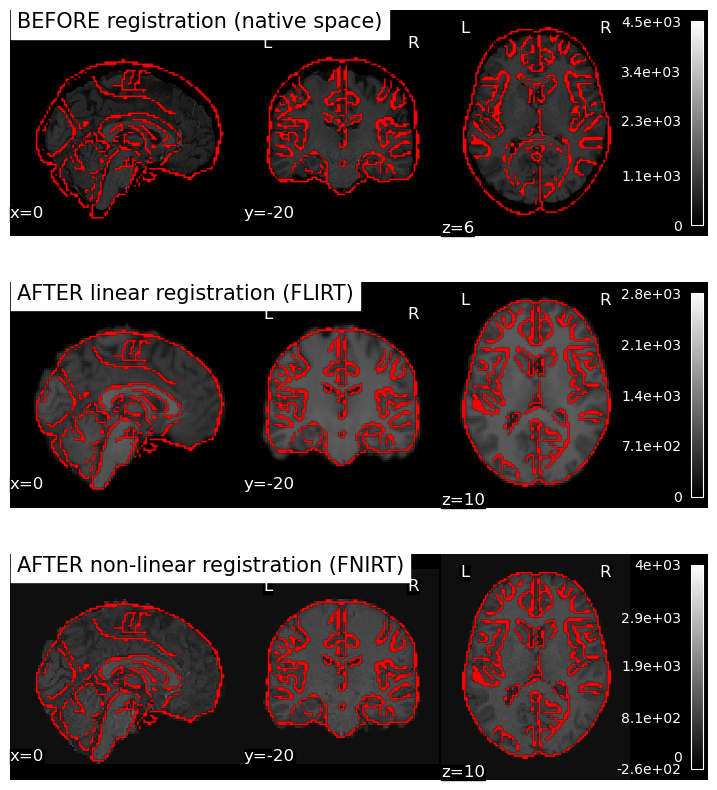

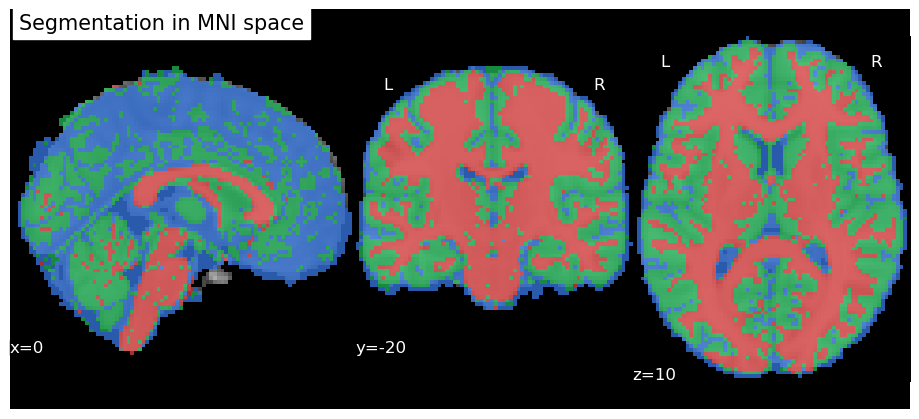

In [6]:
# ===== CELL 3: c) registration to MNI152 with FSL FLIRT (linear) + FNIRT (non-linear) (needs cells 1-2) =====
affine = op.join(out_dir, "T1_to_MNI_affine.mat")              # linear transform (saved)
brain_flirt = op.join(out_dir, "T1w_brain_MNI_linear.nii.gz")  # brain after linear registration
warp = op.join(out_dir, "T1_to_MNI_warp.nii.gz")               # non-linear warp field (saved)
brain_nl = op.join(out_dir, "T1w_brain_MNI_nonlinear.nii.gz")  # brain after non-linear registration
seg_mni = op.join(out_dir, "T1w_seg_MNI.nii.gz")               # segmentation in MNI space

# step 1, FLIRT: 12-parameter affine registration of the brain to the MNI brain
subprocess.run(["flirt", "-in", brain, "-ref", mni_brain, "-out", brain_flirt,
                "-omat", affine, "-dof", "12"], check=True)

# step 2, FNIRT: non-linear registration of the whole head, starting from the affine (takes a few minutes)
subprocess.run(["fnirt", f"--in={t1_reori}", f"--ref={mni_head}", f"--aff={affine}",
                "--config=T1_2_MNI152_2mm", f"--cout={warp}"], check=True)

# apply the warp: skull-stripped brain (smooth interpolation) and segmentation (nearest neighbour keeps labels)
subprocess.run(["applywarp", f"--in={brain}", f"--ref={mni_head}", f"--warp={warp}",
                f"--out={brain_nl}", "--interp=spline"], check=True)
subprocess.run(["applywarp", f"--in={seg}", f"--ref={mni_head}", f"--warp={warp}",
                f"--out={seg_mni}", "--interp=nn"], check=True)

# ---- plot: before / after linear / after non-linear; red lines = edges of the MNI152 brain ----
mni_coords = (0, -20, 10)                                      # slices to show in MNI space
fig, axs = plt.subplots(3, 1, figsize=(9, 10))

d = plotting.plot_anat(brain, cut_coords=coords, axes=axs[0], draw_cross=False,
                       title="BEFORE registration (native space)")
d.add_edges(mni_brain, color="r")                              # MNI edges on top

d = plotting.plot_anat(brain_flirt, cut_coords=mni_coords, axes=axs[1], draw_cross=False,
                       title="AFTER linear registration (FLIRT)")
d.add_edges(mni_brain, color="r")

d = plotting.plot_anat(brain_nl, cut_coords=mni_coords, axes=axs[2], draw_cross=False,
                       title="AFTER non-linear registration (FNIRT)")
d.add_edges(mni_brain, color="r")

fig.savefig(op.join(fig_dir, "3_registration_MNI.png"), dpi=200, bbox_inches="tight")
plt.show()

# ---- plot: segmentation brought to MNI space ----
fig = plt.figure(figsize=(9, 4))
plotting.plot_roi(seg_mni, bg_img=mni_brain, cut_coords=mni_coords, cmap=cmap, vmin=1, vmax=3,
                  alpha=0.7, colorbar=False, draw_cross=False, figure=fig,
                  title="Segmentation in MNI space")
fig.savefig(op.join(fig_dir, "3b_segmentation_MNI.png"), dpi=200, bbox_inches="tight")
plt.show()